# Unveiling the Android App Market: Google Play Store Analysis
**Oasis Infobyte SIP — Data Analytics L2 Task 4** · Steven Manuel Rios

Datasets: **Google Play Store Apps** (Lavanya Gupta, Kaggle, scraped Aug 2018): `googleplaystore.csv` (10,841 apps) and `googleplaystore_user_reviews.csv` (64,295 reviews).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
apps = pd.read_csv("data/googleplaystore.csv"); rev = pd.read_csv("data/googleplaystore_user_reviews.csv")
print(apps.shape, rev.shape); apps.dtypes

(10841, 13) (64295, 5)


App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

## Data cleaning
* Row 10472 is shifted one column to the left (its category is missing), so it is dropped.
* Duplicates: the same app appears several times with different review counts. The row with the **most reviews** (most recent scrape) is kept.
* `Installs` "10,000+" → int. `Price` "\$4.99" → float. `Size` "19M" / "201k" / "Varies with device" → MB float or NaN. `Reviews` → int. `Last Updated` → datetime.
* `Rating` nulls are left as NaN and excluded from rating analysis, since imputing them would bias averages.

In [3]:
n0 = len(apps)
apps = apps[apps["Category"] != "1.9"].copy()
apps["Reviews"] = apps["Reviews"].astype(int)
apps["Installs"] = apps["Installs"].str.replace(r"[+,]", "", regex=True).astype(int)
apps["Price"] = apps["Price"].str.replace("$", "", regex=False).astype(float)
def size_mb(s):
    if s.endswith("M"): return float(s[:-1])
    if s.endswith("k"): return float(s[:-1]) / 1024
    return np.nan
apps["SizeMB"] = apps["Size"].apply(size_mb); apps["Last Updated"] = pd.to_datetime(apps["Last Updated"])
apps = apps.sort_values("Reviews", ascending=False).drop_duplicates("App").reset_index(drop=True)
print(f"{n0} -> {len(apps)} unique apps"); apps.isnull().sum()[lambda s: s > 0]

10841 -> 9659 unique apps


Rating         1463
Type              1
Current Ver       8
Android Ver       2
SizeMB         1228
dtype: int64

## Category analysis

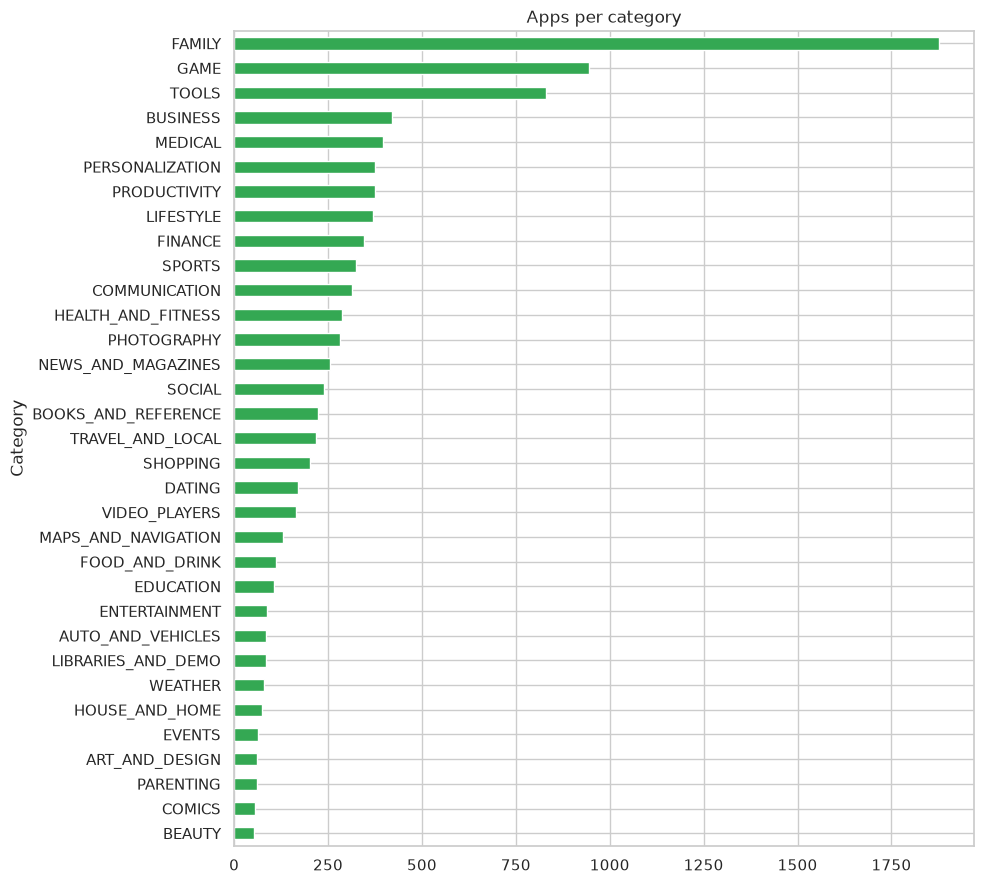

Category
FAMILY      19.4
GAME         9.8
TOOLS        8.6
BUSINESS     4.3
MEDICAL      4.1
Name: count, dtype: float64


In [4]:
cc = apps["Category"].value_counts()
plt.figure(figsize=(10, 9)); cc.sort_values().plot.barh(color="#34a853"); plt.title("Apps per category"); save("category_counts")
print((cc / cc.sum() * 100).head(5).round(1))

## Ratings analysis

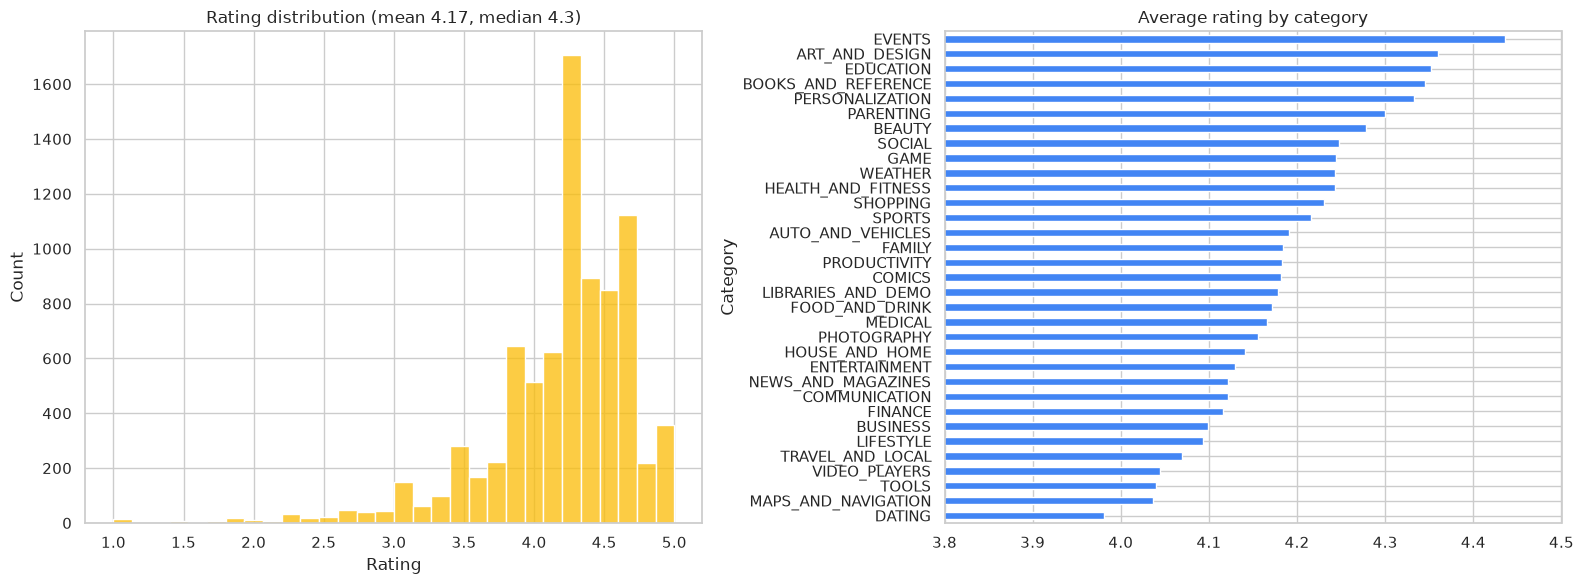

Top: {'EDUCATION': 4.351, 'ART_AND_DESIGN': 4.359, 'EVENTS': 4.436}
Bottom: {'DATING': 3.98, 'MAPS_AND_NAVIGATION': 4.036, 'TOOLS': 4.04}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(apps["Rating"].dropna(), bins=30, ax=ax[0], color="#fbbc05"); ax[0].set_title(f"Rating distribution (mean {apps.Rating.mean():.2f}, median {apps.Rating.median()})")
avg = apps.groupby("Category")["Rating"].mean().sort_values(); avg.plot.barh(ax=ax[1], color="#4285f4"); ax[1].set_xlim(3.8, 4.5); ax[1].set_title("Average rating by category")
save("ratings"); print("Top:", avg.tail(3).round(3).to_dict()); print("Bottom:", avg.head(3).round(3).to_dict())

## Size vs installs

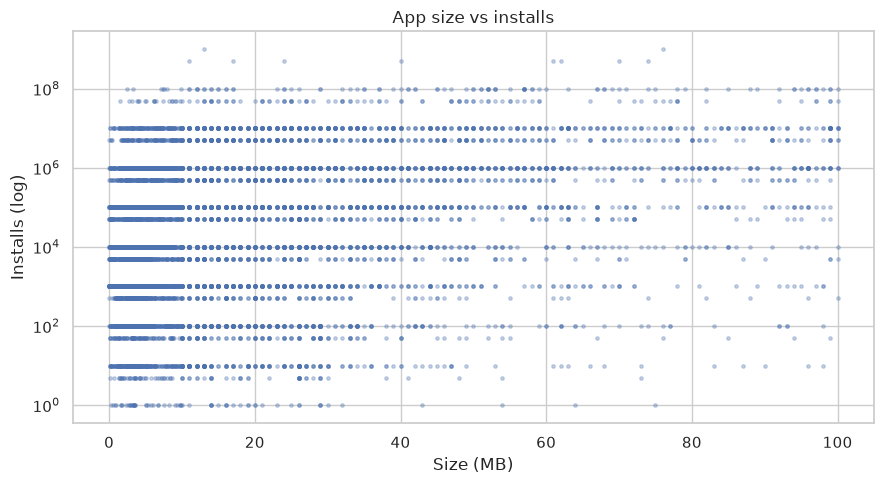

Spearman rho = 0.310 (p = 2.1e-187)


In [6]:
d = apps.dropna(subset=["SizeMB"])
plt.figure(figsize=(9, 5)); plt.scatter(d["SizeMB"], d["Installs"], s=6, alpha=.3); plt.yscale("log"); plt.xlabel("Size (MB)"); plt.ylabel("Installs (log)"); plt.title("App size vs installs"); save("size_vs_installs")
from scipy.stats import spearmanr; r = spearmanr(d["SizeMB"], d["Installs"]); print(f"Spearman rho = {r.statistic:.3f} (p = {r.pvalue:.1e})")

## Pricing analysis

Type
Free    0.922
Paid    0.078
Name: proportion, dtype: float64


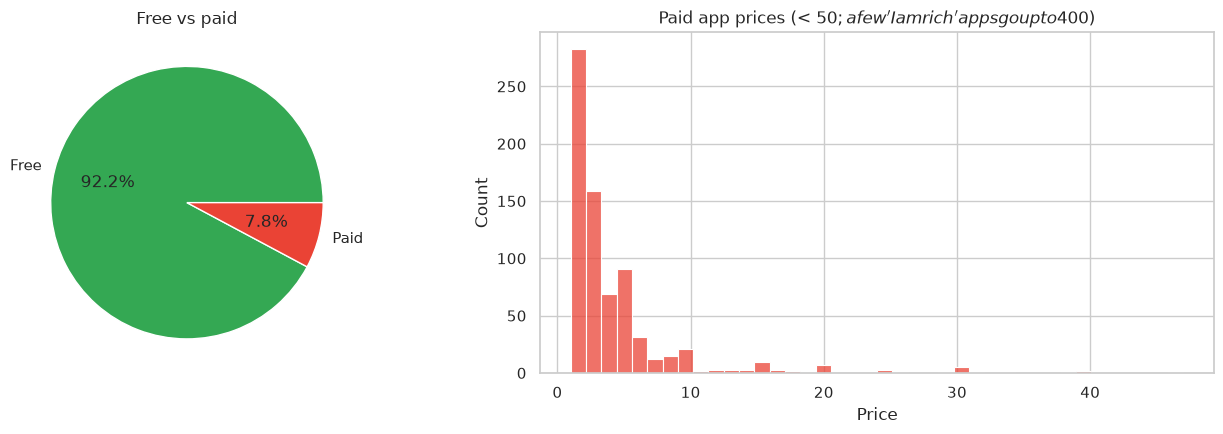

count    754.00
mean      14.06
std       58.82
min        0.99
25%        1.49
50%        2.99
75%        4.99
max      400.00
Name: Price, dtype: float64


In [7]:
paid = apps[apps["Type"] == "Paid"]
print(apps["Type"].value_counts(normalize=True).round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
apps["Type"].value_counts().plot.pie(ax=ax[0], autopct="%1.1f%%", colors=["#34a853", "#ea4335"]); ax[0].set_ylabel(""); ax[0].set_title("Free vs paid")
sns.histplot(paid.loc[paid.Price < 50, "Price"], bins=40, ax=ax[1], color="#ea4335"); ax[1].set_title("Paid app prices (< $50; a few 'I am rich' apps go up to $400)")
save("pricing"); print(paid["Price"].describe().round(2))

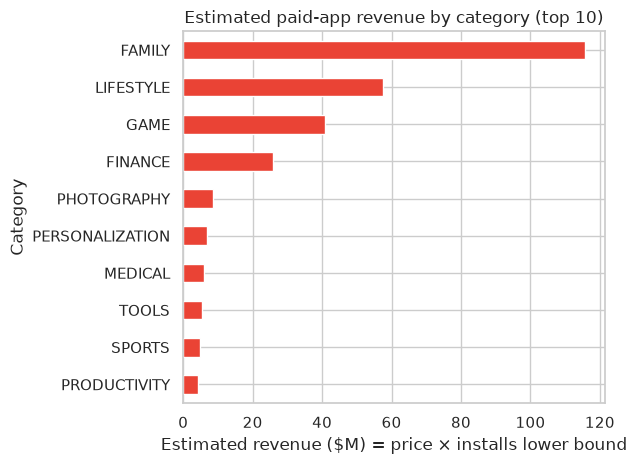

Category
FAMILY             115.68
LIFESTYLE           57.58
GAME                40.69
FINANCE             25.73
PHOTOGRAPHY          8.55
PERSONALIZATION      6.80
MEDICAL              5.96
TOOLS                5.46
SPORTS               4.71
PRODUCTIVITY         4.31
Name: EstRevenue, dtype: float64

In [8]:
paid = paid.assign(EstRevenue=paid["Price"] * paid["Installs"])
rc = paid.groupby("Category")["EstRevenue"].sum().sort_values(ascending=False).head(10) / 1e6
rc[::-1].plot.barh(color="#ea4335"); plt.xlabel("Estimated revenue ($M) = price × installs lower bound"); plt.title("Estimated paid-app revenue by category (top 10)"); save("revenue_by_category"); rc.round(2)

## Sentiment analysis on user reviews (VADER)
VADER is a lexicon and rule-based sentiment model built for short social text. Thresholds: compound ≥ 0.05 is positive, ≤ −0.05 is negative, anything in between is neutral.

In [9]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
rv = rev.dropna(subset=["Translated_Review"]).drop_duplicates().copy()
rv["compound"] = rv["Translated_Review"].apply(lambda t: sia.polarity_scores(t)["compound"])
rv["VADER"] = np.select([rv.compound >= .05, rv.compound <= -.05], ["Positive", "Negative"], "Neutral")
print(len(rv), "reviews"); print(rv["VADER"].value_counts(normalize=True).round(3))
print("Agreement with dataset's own TextBlob label:", (rv["VADER"] == rv["Sentiment"]).mean().round(3))

29692 reviews
VADER
Positive    0.680
Negative    0.198
Neutral     0.122
Name: proportion, dtype: float64
Agreement with dataset's own TextBlob label: 0.765


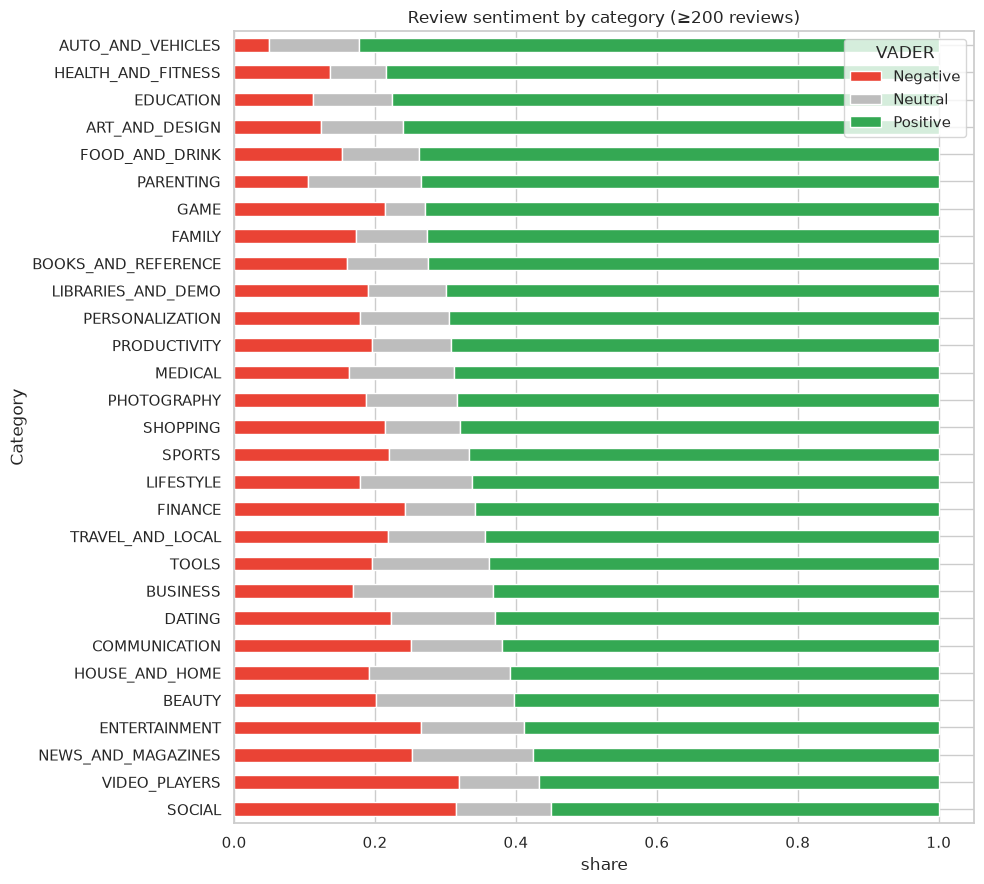

Most positive: {'EDUCATION': 0.776, 'HEALTH_AND_FITNESS': 0.785, 'AUTO_AND_VEHICLES': 0.823}
Most negative: {'ENTERTAINMENT': 0.265, 'SOCIAL': 0.315, 'VIDEO_PLAYERS': 0.319}


In [10]:
m = rv.merge(apps[["App", "Category"]], on="App")
sc = pd.crosstab(m["Category"], m["VADER"], normalize="index").sort_values("Positive")
sc = sc[m["Category"].value_counts().reindex(sc.index) >= 200]  # categories with >= 200 reviews
sc[["Negative", "Neutral", "Positive"]].plot.barh(stacked=True, figsize=(10, 9), color=["#ea4335", "#bdbdbd", "#34a853"]); plt.title("Review sentiment by category (≥200 reviews)"); plt.xlabel("share"); save("sentiment_by_category")
print("Most positive:", sc["Positive"].tail(3).round(3).to_dict()); print("Most negative:", sc["Negative"].sort_values().tail(3).round(3).to_dict())

## Interactive visualisation (plotly)
The chart is also saved as `screenshots/interactive_category_bubble.html`. GitHub does not render plotly output, so open that file in a browser.

In [11]:
import plotly.express as px
agg = apps.groupby("Category").agg(apps=("App", "size"), avg_rating=("Rating", "mean"), median_installs=("Installs", "median")).reset_index()
fig = px.scatter(agg, x="apps", y="avg_rating", size="median_installs", color="Category", hover_name="Category", size_max=60, log_x=True, title="Saturation vs rating (bubble = median installs)")
fig.write_html("screenshots/interactive_category_bubble.html", include_plotlyjs="cdn"); fig.show()

## Key findings
* **Saturation:** FAMILY (19%), GAME (10%) and TOOLS (9%) hold 38% of all apps.
* **Ratings:** ratings are high across the board (mean ≈ 4.17), so a 4.0 is *below average*. EVENTS, ART_AND_DESIGN and EDUCATION rate best, while DATING, MAPS and TOOLS rate worst.
* **Size vs installs:** there is a weak positive correlation (Spearman ρ = 0.31). Bigger apps such as games are installed more, but size is not a barrier.
* **Pricing:** 92% of apps are free. Paid apps have a median price of \$2.99. Estimated paid revenue is dominated by FAMILY (≈\$116M lower bound), then LIFESTYLE (inflated by \$400 "I am rich" novelty apps) and GAME.
* **Reviews (VADER):** 68% positive, 20% negative, 12% neutral (76% agreement with the dataset's own TextBlob labels). AUTO_AND_VEHICLES, HEALTH_AND_FITNESS and EDUCATION draw the most positive reviews. ENTERTAINMENT, SOCIAL and VIDEO_PLAYERS draw the most negative ones.

## 3 data-driven insights for a new app developer
1. **Go where satisfaction is high and competition is moderate.** EDUCATION and HEALTH_AND_FITNESS combine top ratings, very positive reviews and far less saturation than FAMILY or GAME.
2. **Launch free and monetise in-app.** 92% of the market is free and the typical paid price is only \$1–5, so a free download with optional purchases maximises installs, which are what drive revenue.
3. **Quality is the bar, not size.** With the average rating at 4.17, anything under 4.2 stands out negatively. Invest in stability and UX instead of trimming APK size, since size barely affects installs. Social and entertainment apps get the harshest reviews, so enter those categories only with a clear quality advantage.